# TF-IDF (word + char) + XGBoost (spam w klasie pozytywnej)

Wariant `spam_1`: ogólny klasyfikator niechcianych wiadomości, więc phishing i spam należą do klasy pozytywnej (etykieta `label_spam_1`).

- **Cechy:** TF-IDF na n-gramach słów (1-2) i znaków (3-5), po 100 000 najczęstszych n-gramów w każdym słowniku. Następnie selekcja
  chi-kwadrat, bo przy 200 000 cech XGBoost nie mieści się w pamięci. Liczba wybranych cech jest częścią grida.
- **Dobór hiperparametrów:** grid z k-fold CV na zbiorze treningowym. Foldy są rozłączne względem klastrów, a TF-IDF i selekcja cech są
  uczone osobno w każdym foldzie. Kryterium to AUCPR ważone odwrotnością rozmiaru klastra,
  a liczba drzew jest dobierana wczesnym zatrzymaniem.
- **Podział:** 60% train, 30% val, 10% test na poziomie klastrów, taki sam we wszystkich eksperymentach.
- **Próg:** na zbiorze walidacyjnym, największy recall przy FPR ważonym klastrami nie większym niż 1%.
- **Ocena:** zbiór testowy ID i cały korpus OOD, a także każde źródło osobno.

In [ ]:
import itertools
import sys
import time
from pathlib import Path
import numpy as np
import pandas as pd
import xgboost as xgb
from IPython.display import display
from sklearn.metrics import average_precision_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "notebooks"))
from experiment_utils import (
    ID_SOURCES, OOD_SOURCES, TARGET_FPR, WordCharTfidf, cluster_folds, cluster_weights, corpus_metrics, load_corpora,
    plot_confusion_matrices, plot_curves, threshold_at_fpr,
)

EXPERIMENT = "tf_idf_xgb_spam_1"
LABEL = "label_spam_1"
RESULTS = ROOT / "results" / EXPERIMENT
TABLES, FIGURES = RESULTS / "tables", RESULTS / "figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200, "display.max_columns", 50, "display.max_rows", 100, "display.float_format", "{:.4f}".format)

N_FOLDS = 3
FEATURE_COUNTS = (10_000, 20_000)
MAX_DEPTHS = (4, 6, 8)
LEARNING_RATES = (0.05, 0.1)
MAX_ROUNDS = 5000
EARLY_STOPPING_ROUNDS = 100
SEED = 42


def xgb_params(max_depth, learning_rate):
    # max_bin 32, bo przy 64 OOM na GPU
    return {
        "objective": "binary:logistic", "tree_method": "hist", "device": "cuda", "max_bin": 32,
        "max_depth": max_depth, "learning_rate": learning_rate, "seed": SEED,
    }

## Dane i podział

In [2]:
in_domain, out_of_domain = load_corpora()
train, val, test = (in_domain[in_domain.split == name] for name in ("train", "val", "test"))
assert not set(train.cluster) & set(val.cluster) and not set(train.cluster) & set(test.cluster) and not set(val.cluster) & set(test.cluster)
print({name: len(frame) for name, frame in (("train", train), ("val", val), ("test", test), ("ood", out_of_domain))})

{'train': 80679, 'val': 40720, 'test': 13070, 'ood': 6124}


## Grid z k-fold CV

Liczba drzew nie jest częścią siatki, tylko jest dobierana wczesnym zatrzymaniem (early stopping). W każdym foldzie model jest
uczony do `MAX_ROUNDS` drzew i zatrzymywany, gdy AUCPR ważone klastrami na części holdout nie rośnie przez `EARLY_STOPPING_ROUNDS`
kolejnych drzew. Wynik foldu to AUCPR dla najlepszej liczby drzew, a model końcowy dostaje średnią z tych liczb po foldach.

In [3]:
cv_rows = []
cv_start = time.perf_counter()
for fold, (fit_index, holdout_index) in enumerate(cluster_folds(train[LABEL], train.cluster, N_FOLDS, SEED)):
    fit_frame, holdout_frame = train.iloc[fit_index], train.iloc[holdout_index]
    assert not set(fit_frame.cluster) & set(holdout_frame.cluster)
    features = WordCharTfidf().fit(fit_frame.text, fit_frame[LABEL])
    fit_all, holdout_all = features.transform_all(fit_frame.text), features.transform_all(holdout_frame.text)
    holdout_weights = cluster_weights(holdout_frame.cluster)
    for n_features in FEATURE_COUNTS:
        selected = features.selected(n_features)
        dtrain = xgb.DMatrix(fit_all[:, selected], label=fit_frame[LABEL].to_numpy())
        dholdout = xgb.DMatrix(holdout_all[:, selected], label=holdout_frame[LABEL].to_numpy(), weight=holdout_weights)
        for max_depth, learning_rate in itertools.product(MAX_DEPTHS, LEARNING_RATES):
            start = time.perf_counter()
            booster = xgb.train(
                xgb_params(max_depth, learning_rate) | {"eval_metric": "aucpr"}, dtrain, num_boost_round=MAX_ROUNDS,
                evals=[(dholdout, "holdout")], early_stopping_rounds=EARLY_STOPPING_ROUNDS, verbose_eval=False,
            )
            n_estimators = booster.best_iteration + 1
            scores = booster.predict(dholdout, iteration_range=(0, n_estimators))
            cv_rows.append({
                "fold": fold, "n_features": n_features, "max_depth": max_depth, "learning_rate": learning_rate, "n_estimators": n_estimators,
                "aucpr_ważone": average_precision_score(holdout_frame[LABEL], scores, sample_weight=holdout_weights),
                "aucpr": average_precision_score(holdout_frame[LABEL], scores),
            })
            print(f"fold {fold}, {n_features} cech, depth {max_depth}, lr {learning_rate}: {n_estimators} drzew, {time.perf_counter() - start:.0f} s", flush=True)
            del booster
        del dtrain, dholdout
    del features, fit_all, holdout_all
cv_seconds = time.perf_counter() - cv_start

cv_folds = pd.DataFrame(cv_rows)
cv_folds.to_csv(TABLES / "cv_folds.csv", index=False)
GRID_COLUMNS = ["n_features", "max_depth", "learning_rate"]
cv_results = (
    cv_folds.groupby(GRID_COLUMNS)[["aucpr_ważone", "aucpr", "n_estimators"]].agg(["mean", "std"])
    .sort_values(("aucpr_ważone", "mean"), ascending=False)
)
cv_results.columns = [f"{metric}_{statistic}" for metric, statistic in cv_results.columns]
cv_results = cv_results.reset_index()
cv_results.to_csv(TABLES / "cv_results.csv", index=False)
best = cv_results.iloc[0]
print(f"Czas grida: {cv_seconds / 60:.1f} min")
display(cv_results.head(10))

fold 0, 10000 cech, depth 4, lr 0.05: 5000 drzew, 32 s


fold 0, 10000 cech, depth 4, lr 0.1: 3032 drzew, 20 s


fold 0, 10000 cech, depth 6, lr 0.05: 3923 drzew, 39 s


fold 0, 10000 cech, depth 6, lr 0.1: 1938 drzew, 20 s


fold 0, 10000 cech, depth 8, lr 0.05: 2449 drzew, 35 s


fold 0, 10000 cech, depth 8, lr 0.1: 1500 drzew, 22 s


... (28 outputs left out)

fold 2, 20000 cech, depth 8, lr 0.05: 2909 drzew, 82 s


fold 2, 20000 cech, depth 8, lr 0.1: 1251 drzew, 37 s


Czas grida: 33.3 min


,n_features,max_depth,learning_rate,aucpr_ważone_mean,aucpr_ważone_std,aucpr_mean,aucpr_std,n_estimators_mean,n_estimators_std
0,20000,6,0.0500,0.9914,0.0003,0.9937,0.0016,3778.6667,564.6542
1,20000,8,0.0500,0.9913,0.0004,0.9936,0.0014,2744.0000,223.9978
2,20000,6,0.1000,0.9913,0.0004,0.9936,0.0015,2207.3333,283.2125
3,20000,4,0.1000,0.9911,0.0006,0.9936,0.0019,2811.6667,132.1262
4,20000,8,0.1000,0.9911,0.0004,0.9934,0.0015,1329.6667,122.6594
5,20000,4,0.0500,0.9910,0.0005,0.9935,0.0018,4990.6667,2.0817
6,10000,6,0.0500,0.9905,0.0004,0.9929,0.0016,3890.6667,439.3931
7,10000,8,0.1000,0.9904,0.0004,0.9931,0.0017,1609.3333,134.1280
8,10000,6,0.1000,0.9904,0.0004,0.9929,0.0015,2298.3333,312.6057
9,10000,8,0.0500,0.9904,0.0005,0.9929,0.0016,2551.6667,203.4560


## Uczenie modelu końcowego

Model z najlepszymi hiperparametrami jest uczony na całym zbiorze treningowym.

In [4]:
best_params = {
    "n_features": int(best.n_features), "max_depth": int(best.max_depth),
    "learning_rate": float(best.learning_rate), "n_estimators": int(round(best.n_estimators_mean)),
}
start = time.perf_counter()
features = WordCharTfidf().fit(train.text, train[LABEL])
selected = features.selected(best_params["n_features"])
booster = xgb.train(
    xgb_params(best_params["max_depth"], best_params["learning_rate"]),
    xgb.DMatrix(features.transform_all(train.text)[:, selected], label=train[LABEL].to_numpy()),
    num_boost_round=best_params["n_estimators"],
)
training_seconds = time.perf_counter() - start
print(best_params, f"czas uczenia: {training_seconds:.0f} s")


def score(frame):
    return booster.predict(xgb.DMatrix(features.transform_all(frame.text)[:, selected]))

{'n_features': 20000, 'max_depth': 6, 'learning_rate': 0.05, 'n_estimators': 3779} czas uczenia: 272 s


## Dobór progu na zbiorze walidacyjnym

In [5]:
threshold_result = threshold_at_fpr(val[LABEL], score(val), val.cluster)
threshold = threshold_result["próg"]
threshold_table = pd.DataFrame([{
    "docelowy_fpr": TARGET_FPR, **threshold_result, **best_params,
    "aucpr_ważone_cv": best["aucpr_ważone_mean"], "czas_grida_s": cv_seconds, "czas_uczenia_s": training_seconds,
}])
threshold_table.to_csv(TABLES / "threshold.csv", index=False)
display(threshold_table)

,docelowy_fpr,próg,fpr_ważony_val,fpr_val,recall_val,n_features,max_depth,learning_rate,n_estimators,aucpr_ważone_cv,czas_grida_s,czas_uczenia_s
0,0.0100,0.8126,0.0099,0.0348,0.9481,20000,6,0.0500,3779,0.9914,1997.5307,271.9764


## Metryki dla ID i OOD

In [6]:
test_scores, ood_scores = score(test), score(out_of_domain)
corpus_sets = {"ID": (test[LABEL], test_scores), "OOD": (out_of_domain[LABEL], ood_scores)}
metrics = corpus_metrics(corpus_sets, threshold)
metrics.to_csv(TABLES / "metrics.csv", index_label="korpus")
display(metrics)

,n,positives,accuracy,recall,f1,precision,roc_auc,aucpr,fpr
ID,13070.0000,6232.0000,0.9525,0.9127,0.9482,0.9866,0.9944,0.9939,0.0113
OOD,6124.0000,4987.0000,0.7476,0.7465,0.8281,0.9296,0.8339,0.9546,0.2480


## Metryki według źródła

Puste wartości oznaczają metrykę, której nie da się policzyć dla jednej klasy, np. FPR dla Nazario, które ma tylko phishing.

In [7]:
source_sets = {
    name: (test.loc[test.source == name, LABEL], test_scores[(test.source == name).to_numpy()]) for name in ID_SOURCES
} | {
    name: (out_of_domain.loc[out_of_domain.source == name, LABEL], ood_scores[(out_of_domain.source == name).to_numpy()])
    for name in OOD_SOURCES
}
metrics_by_source = corpus_metrics(source_sets, threshold)
metrics_by_source.to_csv(TABLES / "metrics_by_source.csv", index_label="source")
display(metrics_by_source)

,n,positives,accuracy,recall,f1,precision,roc_auc,aucpr,fpr
nazario,918.0000,918.0000,0.9107,0.9107,0.9532,1.0000,NaN,NaN,NaN
nigerian,335.0000,335.0000,0.9851,0.9851,0.9925,1.0000,NaN,NaN,NaN
trec05,5386.0000,2188.0000,0.9521,0.9045,0.9388,0.9758,0.9939,0.9914,0.0153
trec06,1582.0000,361.0000,0.9690,0.8947,0.9295,0.9671,0.9971,0.9906,0.0090
trec07,4849.0000,2430.0000,0.9532,0.9136,0.9514,0.9924,0.9946,0.9942,0.0070
ferb,5601.0000,4707.0000,0.7479,0.7440,0.8322,0.9442,0.8429,0.9658,0.2315
kd10000,60.0000,55.0000,0.6667,0.6364,0.7778,1.0000,1.0000,1.0000,0.0000
nebulon,145.0000,69.0000,0.7241,0.6232,0.6825,0.7544,0.7857,0.7698,0.1842
zeroday,318.0000,156.0000,0.7673,0.9167,0.7944,0.7010,0.9129,0.9310,0.3765


## Macierze pomyłek i krzywe

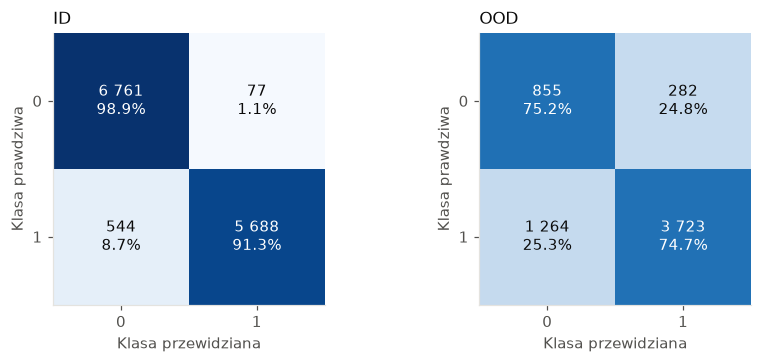

,przewidziane 0,przewidziane 1
prawdziwe 0,6761,77
prawdziwe 1,544,5688


,przewidziane 0,przewidziane 1
prawdziwe 0,855,282
prawdziwe 1,1264,3723


In [8]:
matrices = plot_confusion_matrices(corpus_sets, threshold, FIGURES / "confusion_matrices.pdf")
for name, matrix in matrices.items():
    matrix.to_csv(TABLES / f"confusion_matrix_{name.lower()}.csv")
    display(matrix)

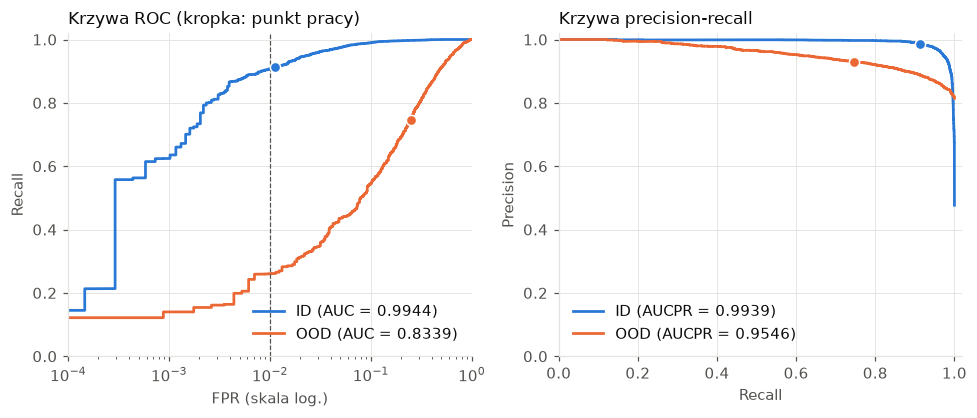

In [9]:
plot_curves(corpus_sets, threshold, FIGURES / "roc_pr_curves.pdf")